In [1]:
import glob
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## individual year

In [2]:
candidates = [1314, 1533, 1569, 1814, 3164, 3323, 5216, 7791]

In [3]:
def path_name(x):
    if x in [1533, 3164]:
        return f'/Users/bjcliang/Desktop/GSS/code/{x}/replication_{x}_time.csv'
    return f'/Users/bjcliang/Desktop/GSS/code/{x}/replication_{x}.csv'
filter_type = lambda x: ('replic' in x.lower()) or ('time-' in x.lower())

In [5]:
result = pd.DataFrame()
for x in candidates:
    data = pd.read_csv(path_name(x))
    temp = data[data['type'].apply(filter_type)][['type', 'year', 'r_sq_adj', 'r_sq']].copy()
    temp['forward_year'] = temp['year']-list(temp['year'])[0]
    temp['forward_rsqadj'] = temp['r_sq_adj']-list(temp['r_sq_adj'])[0]
    temp['neg'] = temp['forward_rsqadj'].apply(lambda x: 1 if x<0 else 0)
    temp['paper'] = x
    result = result.append(temp)
result = result.reset_index(drop=True).copy()

In [6]:
result['type'] = result['type'].apply(lambda x: "Replication" if 'rep' in x.lower() else "Time-Forward Analysis")

array([[1.        , 0.24164193],
       [0.24164193, 1.        ]])

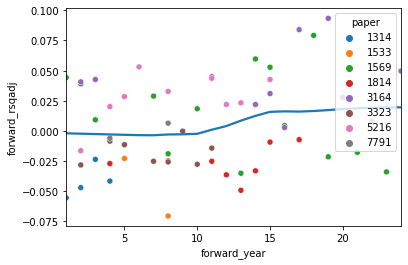

In [7]:
result['paper'] = result['paper'].apply(str)
temp_data = result[result['type']!='Replication']
sns.scatterplot(x='forward_year', y='forward_rsqadj', hue='paper',data=temp_data)
sns.regplot(x='forward_year', y='forward_rsqadj', lowess=True, scatter=False, data=temp_data)
np.corrcoef(temp_data['forward_year'], temp_data['forward_rsqadj'])

In [8]:
result[result['paper']=='1314']

,type,year,r_sq_adj,r_sq,forward_year,forward_rsqadj,neg,paper
0,Replication,1973,0.167867,0.173422,0,0.000000,0,1314
1,Time-Forward Analysis,1974,0.112382,0.118348,1,-0.055484,1,1314
2,Time-Forward Analysis,1975,0.120830,0.126543,2,-0.047036,1,1314
3,Time-Forward Analysis,1976,0.144314,0.149964,3,-0.023553,1,1314
4,Time-Forward Analysis,1977,0.126278,0.132039,4,-0.041589,1,1314


In [29]:
result.head()

,type,year,r_sq_adj,r_sq,forward_year,forward_rsqadj,neg,paper
0,Replication,1973,0.167867,0.173422,0,0.000000,0,1314
1,Time-Forward Analysis,1974,0.112382,0.118348,1,-0.055484,1,1314
2,Time-Forward Analysis,1975,0.120830,0.126543,2,-0.047036,1,1314
3,Time-Forward Analysis,1976,0.144314,0.149964,3,-0.023553,1,1314
4,Time-Forward Analysis,1977,0.126278,0.132039,4,-0.041589,1,1314


<AxesSubplot:xlabel='forward_year'>

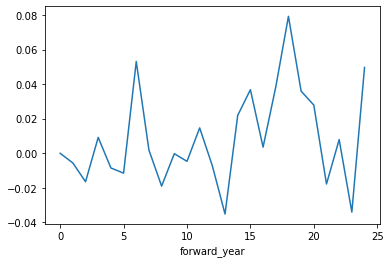

In [12]:
temp = result.groupby('forward_year').median()
sns.lineplot(y=list(temp['forward_rsqadj']), x=temp.index)

In [27]:
result.groupby('forward_year').count().head()

,type,year,r_sq_adj,r_sq,forward_rsqadj,neg,paper
forward_year,,,,,,,
0,8,8,8,8,8,8,8
1,2,2,2,2,2,2,2
2,5,5,5,5,5,5,5
3,3,3,3,3,3,3,3
4,5,5,5,5,5,5,5


In [28]:
temp.head()

,type,year,r_sq_adj,st_year,forward_year,forward_rsqadj,neg,paper
0,Replication,1973_1977,0.112898,1973,0,0.000000,0,2243
1,Time-forward Analysis,1974_1978,0.121321,1974,1,0.008423,0,2243
2,Time-forward Analysis,1975_1980,0.126147,1975,2,0.013250,0,2243
3,Time-forward Analysis,1976_1982,0.138787,1976,3,0.025889,0,2243
4,Time-forward Analysis,1977_1983,0.150548,1977,4,0.037650,0,2243


In [15]:
result[result['type']!='Replication'].groupby('paper').mean()

,year,r_sq_adj,r_sq,forward_year,forward_rsqadj,neg
paper,,,,,,
1314,1975.500000,0.125951,0.131724,2.500000,-0.041916,1.000000
1533,1983.500000,0.113452,0.132032,6.500000,-0.046674,1.000000
1569,1987.142857,0.192721,0.203434,12.142857,0.014884,0.357143
1814,1987.750000,0.030855,0.060544,11.750000,-0.026560,1.000000
3164,1988.818182,0.246334,0.256486,14.818182,0.040586,0.000000
3323,1987.000000,0.042325,0.052251,7.000000,-0.017655,1.000000
5216,1986.444444,0.165738,0.169905,8.444444,0.027706,0.111111
7791,1986.000000,0.324617,0.374355,6.000000,0.000172,0.500000


## Multiple Years

In [16]:
group_candidates = [196, 1686, 4619, 5407, 5839, 7433, 2243]
path_name = lambda x: f'/Users/bjcliang/Desktop/GSS/code/{x}/replication_{x}_time.csv'
filter_type = lambda x: ('replic' in x.lower()) or ('time-' in x.lower())

In [17]:
result_group = pd.DataFrame()
for x in group_candidates:
    data = pd.read_csv(path_name(x)).drop_duplicates()
    temp = data[data['type'].apply(filter_type)][['type', 'year', 'r_sq_adj']].copy()
    temp['st_year'] = temp['year'].apply(lambda x: int(x.split('_')[0]))
    temp['forward_year'] = temp['st_year']-list(temp['st_year'])[0]
    temp['forward_rsqadj'] = temp['r_sq_adj']-list(temp['r_sq_adj'])[0]
    temp['neg'] = temp['forward_rsqadj'].apply(lambda x: 1 if x<0 else 0)
    temp['paper'] = x
    result_group = result_group.append(temp)
result_group = result_group.reset_index(drop=True).copy()

In [18]:
result_group[result_group['type']!='Replication'].groupby('paper').mean()

,r_sq_adj,st_year,forward_year,forward_rsqadj,neg
paper,,,,,
196,0.319013,1978.000000,4.000000,-0.020599,1.000000
1686,0.100536,1984.000000,11.000000,0.004090,0.388889
2243,0.124551,1982.266667,9.266667,0.011653,0.266667
4619,0.041113,1982.266667,9.266667,-0.016423,1.000000
5407,0.026003,1977.555556,5.555556,-0.003492,0.666667
5839,0.230585,1984.727273,7.727273,-0.017746,0.909091
7433,0.275487,1982.266667,9.266667,-0.008441,0.666667


array([[ 1.        , -0.30942502],
       [-0.30942502,  1.        ]])

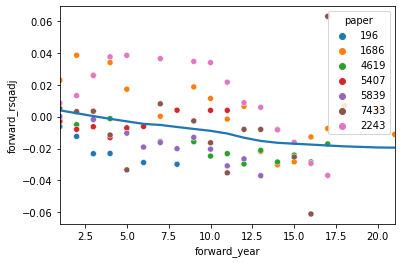

In [19]:
result_group['paper'] = result_group['paper'].apply(str)
temp_data = result_group[result_group['type']!='Replication']
sns.scatterplot(x='forward_year', y='forward_rsqadj', hue='paper',data=temp_data)
sns.regplot(x='forward_year', y='forward_rsqadj', lowess=True, scatter=False, data=temp_data)
np.corrcoef(temp_data['forward_year'], temp_data['forward_rsqadj'])

## All (group+individual)

In [20]:
all_result = result.append(result_group)

array([[1.        , 0.02785349],
       [0.02785349, 1.        ]])

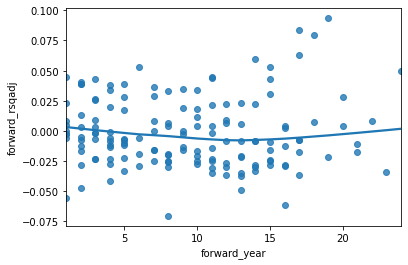

In [21]:
temp_data = all_result[all_result['type']!='Replication']
sns.regplot(x='forward_year', y='forward_rsqadj', lowess=True, data=temp_data)
np.corrcoef(temp_data['forward_year'], temp_data['forward_rsqadj'])

In [26]:
temp_data.groupby('forward_year').mean().head()

,r_sq_adj,r_sq,forward_rsqadj,neg,st_year
forward_year,,,,,
1,0.169775,0.172944,0.001559,0.444444,1974.571429
2,0.153375,0.152694,0.001613,0.545455,1975.000000
3,0.177040,0.198432,0.005070,0.500000,1976.571429
4,0.147945,0.147724,-0.003660,0.727273,1977.000000
5,0.130919,0.127147,-0.000944,0.666667,1978.500000


In [23]:
temp_data['neg'].mean()

0.5918367346938775

First ten years

array([[ 1.        , -0.09773271],
       [-0.09773271,  1.        ]])

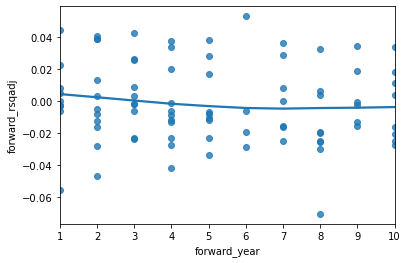

In [24]:
temp_data = all_result[all_result['type']!='Replication']
temp_data = temp_data[temp_data['forward_year']<=10]
sns.regplot(x='forward_year', y='forward_rsqadj', lowess=True, data=temp_data)
np.corrcoef(temp_data['forward_year'], temp_data['forward_rsqadj'])

## Feb 6: 
1. proportion of significant betas
2. sum of absolute beta (for significant ones in the orginal model)

In [3]:
def get_data(x):
    try: 
        return pd.read_csv(f'/Users/bjcliang/Desktop/GSS/code/{x}/replication_{x}_time.csv')
    except FileNotFoundError:
        return pd.read_csv(f'/Users/bjcliang/Desktop/GSS/code/{x}/replication_{x}.csv')

candidates = [1314, 1533, 1569, 1814, 3164, 3323, 5216, 7791]
group_candidates = [196, 1686, 4619, 5407, 5839, 7433, 2243]
filter_type = lambda x: ('replic' in x.lower()) or ('time-' in x.lower())

In [87]:
def perc_sig_beta(row, org_pvalues):
    
    betas, pvalues = [], []

    for i in dict(row):
        if 'beta' in i: betas.append(row[i])
        if 'pvalue' in i: pvalues.append(row[i])
    
    #if x == 4619: print(org_pvalues, pvalues)
    
    betas = np.array([float(i) for i in betas])
    pvalues = np.array([float(i) for i in pvalues])
    org_pvalues = np.array([float(i) for i in org_pvalues]) 
    
    if (org_pvalues<=0.05).sum()==0: print(x, org_pvalues)   
    perc_sig = (pvalues<=0.05).mean()
    mean_abs = abs(betas).mean()
    mean_abs_sig = abs(betas[org_pvalues<=0.05]).mean()
    return perc_sig, mean_abs, mean_abs_sig

## Significant variable selected by the replication year

In [88]:
result = pd.DataFrame()
for x in candidates + group_candidates:
    if x == 196: continue
    data = get_data(x)
    temp = data[data['type'].apply(filter_type)].copy()
    
    res = []; switch = False; org_pvalues = []
    for i, row in temp.iterrows(): 
        if switch and row['type'] == 'Replication': 
            res.append((np.nan, np.nan, np.nan))
        elif row['type'] == 'Replication': 
            switch=True
            org_pvalues = [row[i] for i in dict(row) if 'pvalue' in i]
            res.append(perc_sig_beta(row, org_pvalues))
        else: 
            res.append(perc_sig_beta(row, org_pvalues))
    temp = temp[['type', 'year', 'r_sq_adj']]
    temp['paper'] = x
    
    if x in candidates: temp['forward_year'] = temp['year']-list(temp['year'])[0]
    else:
        st_year = temp['year'].apply(lambda x: int(x.split('_')[0]))
        temp['forward_year'] = st_year-list(st_year)[0]
    
    temp['perc_sig'] = [i[0] for i in res]
    temp['mean_abs'] = [i[1] for i in res]
    temp['mean_abs_sig'] = [i[2] for i in res]
    
    temp['forward_perc_sig'] = temp['perc_sig']-list(temp['perc_sig'])[0]
    temp['forward_mean_abs'] = temp['mean_abs']-list(temp['mean_abs'])[0]
    temp['forward_mean_abs_sig'] = temp['mean_abs_sig']-list(temp['mean_abs_sig'])[0]
    
    temp['forward_rsqadj'] = temp['r_sq_adj']-list(temp['r_sq_adj'])[0]
    temp['neg'] = temp['forward_mean_abs_sig'].apply(lambda x: 1 if x<0 else 0)
    
    result = result.append(temp)

result = result.reset_index(drop=True).copy()

array([[ 1.        , -0.26592075],
       [-0.26592075,  1.        ]])

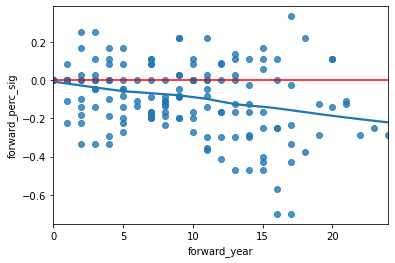

In [89]:
temp_data = result[result['type']!='Replication'].dropna(subset=['forward_perc_sig'])
x = sns.regplot(x='forward_year', y='forward_perc_sig', lowess=True, data=result)
x.axhline(0, color='red')
np.corrcoef(temp_data['forward_year'], temp_data['forward_perc_sig'])

array([[1.        , 0.20843682],
       [0.20843682, 1.        ]])

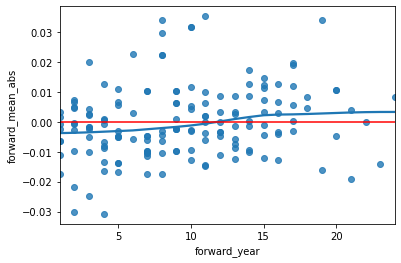

In [90]:
temp_data = result[result['type']!='Replication'].dropna(subset=['forward_mean_abs'])
x=sns.regplot(x='forward_year', y='forward_mean_abs', lowess=True, data=temp_data)
x.axhline(0, color='red')
np.corrcoef(temp_data['forward_year'], temp_data['forward_mean_abs'])

array([[ 1.        , -0.17990036],
       [-0.17990036,  1.        ]])

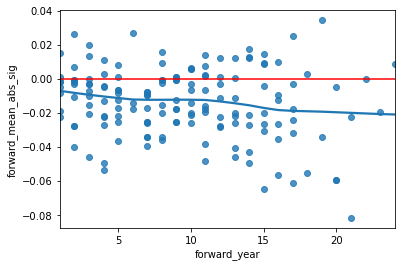

In [32]:
temp_data = result[result['type']!='Replication'].dropna(subset=['forward_mean_abs_sig'])
x = sns.regplot(x='forward_year', y='forward_mean_abs_sig', lowess=True, data=temp_data)
x.axhline(0, color='red')
np.corrcoef(temp_data['forward_year'], temp_data['forward_mean_abs_sig'])

In [ ]:
?significant decline: regression
left and right hand side t-test

## Significant Variables selected by original model

In [91]:
result = pd.DataFrame()
dict_org_pvalues = dict()
for x in candidates + group_candidates:
    if x in [196, 1533]: continue
    data = pd.read_csv(f'/Users/bjcliang/Desktop/GSS/code/{x}/replication_{x}.csv')
    temp = data.copy()
    
    res = []; org_pvalues = []
    for i, row in temp.iterrows(): 
        
        if row['type'].lower() == 'original':
            helper = [row[i] for i in dict(row) if 'pvalue' in i]
            for i in helper:
                if i != i: org_pvalues.append(100)
                elif type(i) == float: org_pvalues.append(i)
                elif type(i) == int: org_pvalues.append(i)
                elif type(i) == str: 
                    if '*' in i: org_pvalues.append(0)
                    else: print(i)
            if x == 4619: org_pvalues.pop(-2)
            dict_org_pvalues[x] = org_pvalues
            break

In [96]:
result = pd.DataFrame()
for x in candidates + group_candidates:
    if x in [196, 1533]: continue
    data = get_data(x)
    temp = data[data['type'].apply(filter_type)].copy()
    
    res = []; switch = False; org_pvalues = []
    for i, row in temp.iterrows(): 
        if switch and row['type'] == 'Replication': 
            res.append((np.nan, np.nan, np.nan))
        elif row['type'] == 'Replication': 
            switch=True
            res.append(perc_sig_beta(row, dict_org_pvalues[x]))
        else: 
            res.append(perc_sig_beta(row, dict_org_pvalues[x]))
    
    temp = temp[['type', 'year', 'r_sq_adj']]
    temp['paper'] = x
    
    if x in candidates: temp['forward_year'] = temp['year']-list(temp['year'])[0]
    else:
        st_year = temp['year'].apply(lambda x: int(x.split('_')[0]))
        temp['forward_year'] = st_year-list(st_year)[0]
    
    temp['perc_sig'] = [i[0] for i in res]
    temp['mean_abs'] = [i[1] for i in res]
    temp['mean_abs_sig'] = [i[2] for i in res]
    
    temp['forward_perc_sig'] = temp['perc_sig']-list(temp['perc_sig'])[0]
    temp['forward_mean_abs'] = temp['mean_abs']-list(temp['mean_abs'])[0]
    temp['forward_mean_abs_sig'] = temp['mean_abs_sig']-list(temp['mean_abs_sig'])[0]
    
    temp['forward_rsqadj'] = temp['r_sq_adj']-list(temp['r_sq_adj'])[0]
    temp['neg'] = temp['forward_mean_abs_sig'].apply(lambda x: 1 if x<0 else 0)
    
    result = result.append(temp)

result = result.reset_index(drop=True).copy()

array([[1.        , 0.02274468],
       [0.02274468, 1.        ]])

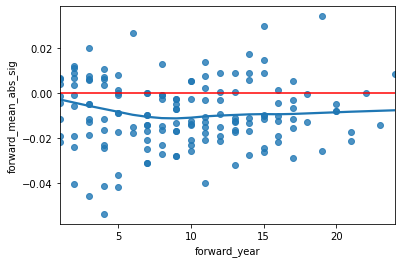

In [97]:
temp_data = result[result['type']!='Replication'].dropna(subset=['forward_mean_abs_sig'])
x = sns.regplot(x='forward_year', y='forward_mean_abs_sig', lowess=True, data=temp_data)
x.axhline(0, color='red')
np.corrcoef(temp_data['forward_year'], temp_data['forward_mean_abs_sig'])